In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.metrics import (classification_report, confusion_matrix, precision_recall_fscore_support,
                             roc_auc_score, roc_curve, accuracy_score)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)

In [2]:
# File paths

train_file = "CICIOT23/train/train.csv"
val_file = "CICIOT23/validation/validation.csv"
test_file = "CICIOT23/test/test.csv" 

In [3]:
# ---- Experiment settings --------------------------------------------------------------
LABEL_MODE   = "8"     # "34" = all classes, "8" = attack families (recommended), "2" = benign vs attack
TRAIN_FRAC   = 0.25    # fraction of the 5.49M training rows to use (1.0 = everything; needs ~3 GB RAM)
EVAL_FRAC    = 1.0     # fraction of validation / test rows to use
EPOCHS       = 15
BATCH_SIZE   = 1024
OUT_DIR      = "outputs_week6"   # figures and tables are saved here for the Week 7 report
os.makedirs(OUT_DIR, exist_ok=True)
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPUs: []


In [4]:
#Load Data 
def load_csv(path, frac=1.0, chunksize=500_000, seed=SEED):
    header = pd.read_csv(path, nrows=0).columns
    dtypes = {c: "float32" for c in header if c != "label"}
    parts = []
    for chunk in pd.read_csv(path, dtype=dtypes, chunksize=chunksize):
        if frac < 1.0:
            chunk = chunk.sample(frac=frac, random_state=seed)
        parts.append(chunk)
    return pd.concat(parts, ignore_index=True)

t0 = time.time()
train_df = load_csv(train_file, TRAIN_FRAC)
val_df   = load_csv(val_file,   EVAL_FRAC)
test_df  = load_csv(test_file,  EVAL_FRAC)
print(f"train {train_df.shape} | val {val_df.shape} | test {test_df.shape} | loaded in {time.time()-t0:.0f}s")
print("Missing values (train):", int(train_df.isna().sum().sum()))
train_df.head()

train (1372993, 47) | val (1176851, 47) | test (1176851, 47) | loaded in 52s
Missing values (train): 0


,flow_duration,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,...,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight,label
0,0.000000,54.080002,6.00,67.820000,2.667762,2.667762,0.0,0.0,0.0,0.0,...,0.218252,54.080002,83071568.0,9.5,10.401771,0.309044,0.323113,0.15,141.550003,DDoS-TCP_Flood
1,0.000000,53.459999,5.94,63.360001,2.863916,2.863916,0.0,0.0,0.0,0.0,...,0.013077,54.060001,83331040.0,9.5,10.392304,0.000000,0.000000,0.00,141.550003,DDoS-PSHACK_Flood
2,0.000000,0.000000,1.00,64.000000,73.618507,73.618507,0.0,0.0,0.0,0.0,...,0.000000,42.000000,83150328.0,9.5,9.165152,0.000000,0.000000,0.00,141.550003,DDoS-ICMP_Flood
3,0.168951,25395.000000,17.00,64.000000,6754.834473,6754.834473,0.0,0.0,0.0,0.0,...,0.000000,50.000000,83106168.0,9.5,10.000000,0.000000,0.000000,0.00,141.550003,DDoS-UDP_Flood
4,0.000000,0.000000,1.00,64.000000,1.005389,1.005389,0.0,0.0,0.0,0.0,...,0.000000,42.000000,83127976.0,9.5,9.165152,0.000000,0.000000,0.00,141.550003,DDoS-ICMP_Flood


In [5]:
#Lable Grouping 
FAMILY = {
 "BenignTraffic": "Benign",
 "MITM-ArpSpoofing": "Spoofing", "DNS_Spoofing": "Spoofing",
 "DictionaryBruteForce": "BruteForce",
 "Recon-HostDiscovery": "Recon", "Recon-OSScan": "Recon", "Recon-PortScan": "Recon",
 "Recon-PingSweep": "Recon", "VulnerabilityScan": "Recon",
 "BrowserHijacking": "Web", "SqlInjection": "Web", "CommandInjection": "Web", "XSS": "Web",
 "Backdoor_Malware": "Web", "Uploading_Attack": "Web",
}
def map_label(l):
    if LABEL_MODE == "34": return l
    if LABEL_MODE == "2":  return "Benign" if l == "BenignTraffic" else "Attack"
    if l in FAMILY: return FAMILY[l]
    if l.startswith("DDoS"):  return "DDoS"
    if l.startswith("DoS"):   return "DoS"
    if l.startswith("Mirai"): return "Mirai"
    return l

for d in (train_df, val_df, test_df):
    d["target"] = d["label"].map(map_label)

classes = sorted(train_df["target"].unique())
cls2id = {c: i for i, c in enumerate(classes)}
for d in (train_df, val_df, test_df):
    d["y"] = d["target"].map(cls2id).astype("int64")

print("Classes:", classes)
train_df["target"].value_counts()

Classes: ['Benign', 'BruteForce', 'DDoS', 'DoS', 'Mirai', 'Recon', 'Spoofing', 'Web']


target
DDoS          999822
DoS           237391
Mirai          77521
Benign         32546
Spoofing       14377
Recon          10257
Web              720
BruteForce       359
Name: count, dtype: int64

In [6]:
#Pre-Processing 
feature_cols = [c for c in train_df.columns if c not in ("label", "target", "y")]
const_cols = [c for c in feature_cols if train_df[c].nunique() <= 1]
feature_cols = [c for c in feature_cols if c not in const_cols]
print("Dropped constant columns:", const_cols, "| remaining features:", len(feature_cols))

skewed = [c for c in feature_cols if train_df[c].max() > 100]
print("log1p applied to", len(skewed), "heavy-tailed columns")

def prepare(df):
    X = df[feature_cols].copy()
    X[skewed] = np.log1p(X[skewed].clip(lower=0))
    return X.values.astype("float32")

X_train, X_val, X_test = prepare(train_df), prepare(val_df), prepare(test_df)
y_train, y_val, y_test = train_df["y"].values, val_df["y"].values, test_df["y"].values

scaler = StandardScaler().fit(X_train)
X_train, X_val, X_test = [scaler.transform(a).astype("float32") for a in (X_train, X_val, X_test)]
n_features, n_classes = X_train.shape[1], len(classes)
print(X_train.shape, X_val.shape, X_test.shape)

Dropped constant columns: ['cwr_flag_number', 'Telnet', 'SMTP', 'IRC'] | remaining features: 42
log1p applied to 18 heavy-tailed columns
(1372993, 42) (1176851, 42) (1176851, 42)


In [7]:
#CLass imbalance
cw = compute_class_weight("balanced", classes=np.arange(n_classes), y=y_train)
class_weight = {i: float(np.sqrt(w)) for i, w in enumerate(cw)}
print({classes[i]: round(w, 2) for i, w in class_weight.items()})

{'Benign': 2.3, 'BruteForce': 21.86, 'DDoS': 0.41, 'DoS': 0.85, 'Mirai': 1.49, 'Recon': 4.09, 'Spoofing': 3.46, 'Web': 15.44}


In [8]:
# 6. Model 1  Multi-Layer Perceptron (neural network)
def build_mlp():
    m = keras.Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(256, activation="relu"), layers.BatchNormalization(), layers.Dropout(0.3),
        layers.Dense(128, activation="relu"), layers.BatchNormalization(), layers.Dropout(0.3),
        layers.Dense(64,  activation="relu"),
        layers.Dense(n_classes, activation="softmax"),
    ], name="MLP")
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

mlp = build_mlp()
mlp.summary()

Model: "MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        11,008 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 54,216 (211.78 KB)

 Trainable params: 53,448 (208.78 KB)

 Non-trainable params: 768 (3.00 KB)

In [ ]:
#  Model 2 – 1D Convolutional Neural Network (deep learning)


In [9]:
def build_cnn():
    m = keras.Sequential([
        layers.Input(shape=(n_features, 1)),
        layers.Conv1D(64, 3, padding="same", activation="relu"), layers.BatchNormalization(),
        layers.MaxPooling1D(2),
        layers.Conv1D(128, 3, padding="same", activation="relu"), layers.BatchNormalization(),
        layers.MaxPooling1D(2),
        layers.Conv1D(128, 3, padding="same", activation="relu"),
        layers.GlobalAveragePooling1D(),
        layers.Dense(128, activation="relu"), layers.Dropout(0.3),
        layers.Dense(n_classes, activation="softmax"),
    ], name="CNN1D")
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

cnn = build_cnn()
cnn.summary()

Model: "CNN1D"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 42, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 42, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 21, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 21, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 21, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 10, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 10, 128)        │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 92,552 (361.53 KB)

 Trainable params: 92,168 (360.03 KB)

 Non-trainable params: 384 (1.50 KB)

In [10]:
#Training
def train(model, Xtr, Xv, name):
    cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
           keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1)]
    t0 = time.time()
    h = model.fit(Xtr, y_train, validation_data=(Xv, y_val), epochs=EPOCHS, batch_size=BATCH_SIZE,
                  class_weight=class_weight, callbacks=cbs, verbose=2)
    print(f"{name}: trained in {(time.time()-t0)/60:.1f} min")
    return h

hist_mlp = train(mlp, X_train, X_val, "MLP")

Epoch 1/15
1341/1341 - 44s - 33ms/step - accuracy: 0.8528 - loss: 0.3134 - val_accuracy: 0.8761 - val_loss: 0.3020 - learning_rate: 0.0010
Epoch 2/15
1341/1341 - 36s - 27ms/step - accuracy: 0.8745 - loss: 0.2649 - val_accuracy: 0.8823 - val_loss: 0.2840 - learning_rate: 0.0010
Epoch 3/15
1341/1341 - 37s - 28ms/step - accuracy: 0.8820 - loss: 0.2534 - val_accuracy: 0.8893 - val_loss: 0.2710 - learning_rate: 0.0010
Epoch 4/15
1341/1341 - 31s - 23ms/step - accuracy: 0.8858 - loss: 0.2472 - val_accuracy: 0.8942 - val_loss: 0.2632 - learning_rate: 0.0010
Epoch 5/15
1341/1341 - 27s - 20ms/step - accuracy: 0.8882 - loss: 0.2441 - val_accuracy: 0.8959 - val_loss: 0.2637 - learning_rate: 0.0010
Epoch 6/15
1341/1341 - 42s - 31ms/step - accuracy: 0.8896 - loss: 0.2409 - val_accuracy: 0.8968 - val_loss: 0.2575 - learning_rate: 0.0010
Epoch 7/15
1341/1341 - 25s - 19ms/step - accuracy: 0.8910 - loss: 0.2392 - val_accuracy: 0.8971 - val_loss: 0.2578 - learning_rate: 0.0010
Epoch 8/15
1341/1341 - 69s 

In [13]:
# CNN expects a channel dimension: (samples, features, 1)
X_train_c, X_val_c, X_test_c = X_train[..., None], X_val[..., None], X_test[..., None]
hist_cnn = train(cnn, X_train_c, X_val_c, "CNN1D")

Epoch 1/15
1341/1341 - 159s - 119ms/step - accuracy: 0.8984 - loss: 0.2256 - val_accuracy: 0.9028 - val_loss: 0.2482 - learning_rate: 5.0000e-04
Epoch 2/15
1341/1341 - 114s - 85ms/step - accuracy: 0.8994 - loss: 0.2233 - val_accuracy: 0.9022 - val_loss: 0.2508 - learning_rate: 5.0000e-04
Epoch 3/15

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
1341/1341 - 142s - 106ms/step - accuracy: 0.9000 - loss: 0.2214 - val_accuracy: 0.8999 - val_loss: 0.2558 - learning_rate: 5.0000e-04
Epoch 4/15
1341/1341 - 117s - 87ms/step - accuracy: 0.9018 - loss: 0.2158 - val_accuracy: 0.9056 - val_loss: 0.2351 - learning_rate: 2.5000e-04
Epoch 5/15
1341/1341 - 118s - 88ms/step - accuracy: 0.9020 - loss: 0.2142 - val_accuracy: 0.9066 - val_loss: 0.2323 - learning_rate: 2.5000e-04
Epoch 6/15
1341/1341 - 118s - 88ms/step - accuracy: 0.9024 - loss: 0.2127 - val_accuracy: 0.9037 - val_loss: 0.2396 - learning_rate: 2.5000e-04
Epoch 7/15

Epoch 7: ReduceLROnPlateau reducing learning 

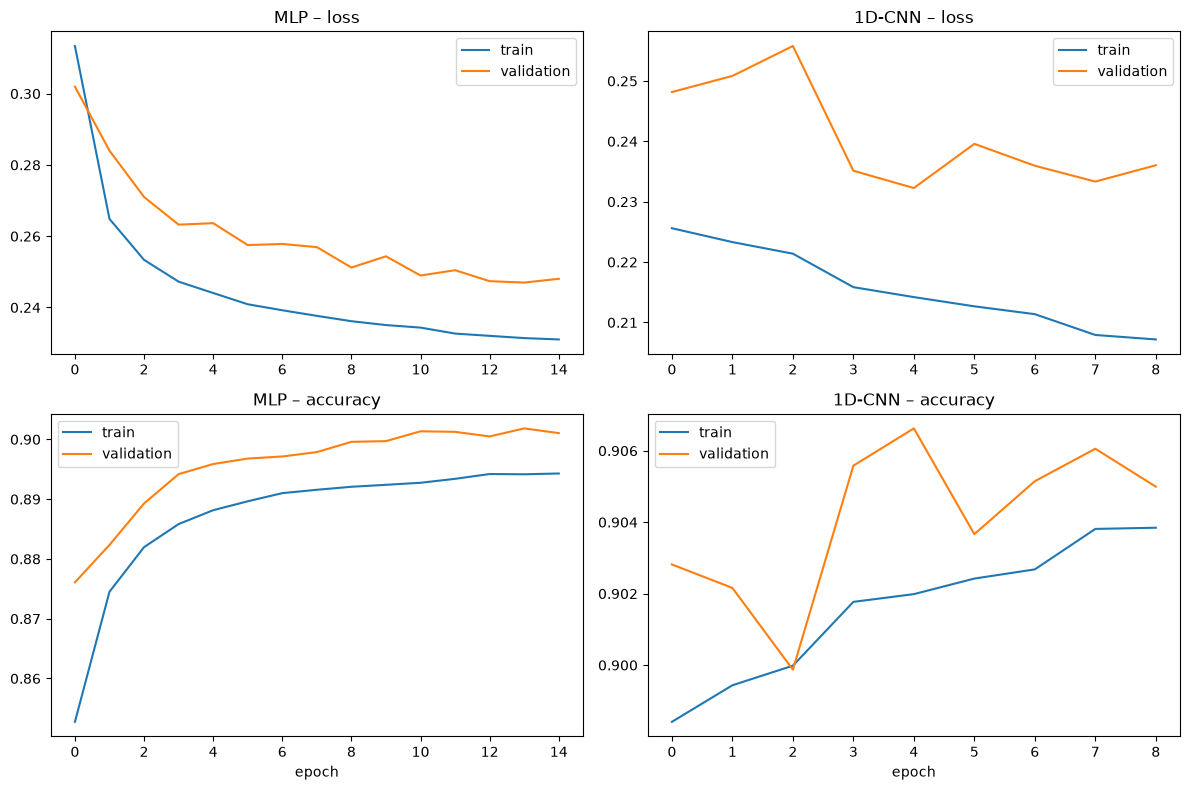

In [14]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for j, (h, n) in enumerate([(hist_mlp, "MLP"), (hist_cnn, "1D-CNN")]):
    ax[0, j].plot(h.history["loss"], label="train"); ax[0, j].plot(h.history["val_loss"], label="validation")
    ax[0, j].set_title(f"{n} – loss"); ax[0, j].legend()
    ax[1, j].plot(h.history["accuracy"], label="train"); ax[1, j].plot(h.history["val_accuracy"], label="validation")
    ax[1, j].set_title(f"{n} – accuracy"); ax[1, j].legend()
    ax[1, j].set_xlabel("epoch")
plt.tight_layout();  plt.show()

In [15]:
#Evaluation 
def evaluate(model, X, y, name, split):
    proba = model.predict(X, batch_size=4096, verbose=0)
    pred = proba.argmax(1)
    p_m, r_m, f_m, _ = precision_recall_fscore_support(y, pred, average="macro", zero_division=0)
    p_w, r_w, f_w, _ = precision_recall_fscore_support(y, pred, average="weighted", zero_division=0)
    present = np.unique(y)                       # AUC only defined for classes present in y
    if n_classes == 2:
        auc = roc_auc_score(y, proba[:, 1])
    else:
        auc = roc_auc_score(label_binarize(y, classes=np.arange(n_classes))[:, present],
                            proba[:, present], average="macro")
    row = dict(model=name, split=split, accuracy=accuracy_score(y, pred),
               precision_macro=p_m, recall_macro=r_m, f1_macro=f_m,
               precision_weighted=p_w, recall_weighted=r_w, f1_weighted=f_w, auc_roc_macro=auc)
    return row, pred, proba

results, preds = [], {}
for name, model, Xv, Xt in [("MLP", mlp, X_val, X_test), ("1D-CNN", cnn, X_val_c, X_test_c)]:
    for split, X, y in [("validation", Xv, y_val), ("test", Xt, y_test)]:
        row, pred, proba = evaluate(model, X, y, name, split)
        results.append(row); preds[(name, split)] = (pred, proba)

results_df = pd.DataFrame(results).round(4)
results_df.to_csv(f"{OUT_DIR}/metrics_summary.csv", index=False)
results_df

,model,split,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,auc_roc_macro
0,MLP,validation,0.9018,0.7433,0.6481,0.6700,0.8979,0.9018,0.8986,0.9856
1,MLP,test,0.9013,0.7482,0.6525,0.6767,0.8973,0.9013,0.8980,0.9856
2,1D-CNN,validation,0.9066,0.7110,0.6676,0.6821,0.9032,0.9066,0.9034,0.9868
3,1D-CNN,test,0.9056,0.7176,0.6729,0.6883,0.9022,0.9056,0.9024,0.9868


In [16]:
# Per-class precision / recall / F1 on the TEST set
for name in ("MLP", "1D-CNN"):
    pred, _ = preds[(name, "test")]
    print(f"\n===== {name} – test set =====")
    rep = classification_report(y_test, pred, labels=np.arange(n_classes), target_names=classes,
                                digits=4, zero_division=0, output_dict=True)
    pd.DataFrame(rep).T.round(4).to_csv(f"{OUT_DIR}/classification_report_{name}.csv")
    print(classification_report(y_test, pred, labels=np.arange(n_classes), target_names=classes,
                                digits=4, zero_division=0))


===== MLP – test set =====
              precision    recall  f1-score   support

      Benign     0.8397    0.9178    0.8770     27709
  BruteForce     0.7614    0.2100    0.3292       319
        DDoS     0.9224    0.9569    0.9393    855981
         DoS     0.7889    0.6617    0.7197    204245
       Mirai     0.9952    0.9940    0.9946     66749
       Recon     0.6674    0.6544    0.6609      8812
    Spoofing     0.7545    0.7041    0.7284     12410
         Web     0.2559    0.1214    0.1647       626

    accuracy                         0.9013   1176851
   macro avg     0.7482    0.6525    0.6767   1176851
weighted avg     0.8973    0.9013    0.8980   1176851


===== 1D-CNN – test set =====
              precision    recall  f1-score   support

      Benign     0.8419    0.9256    0.8818     27709
  BruteForce     0.4940    0.2602    0.3409       319
        DDoS     0.9243    0.9607    0.9421    855981
         DoS     0.8052    0.6695    0.7311    204245
       Mirai     0.

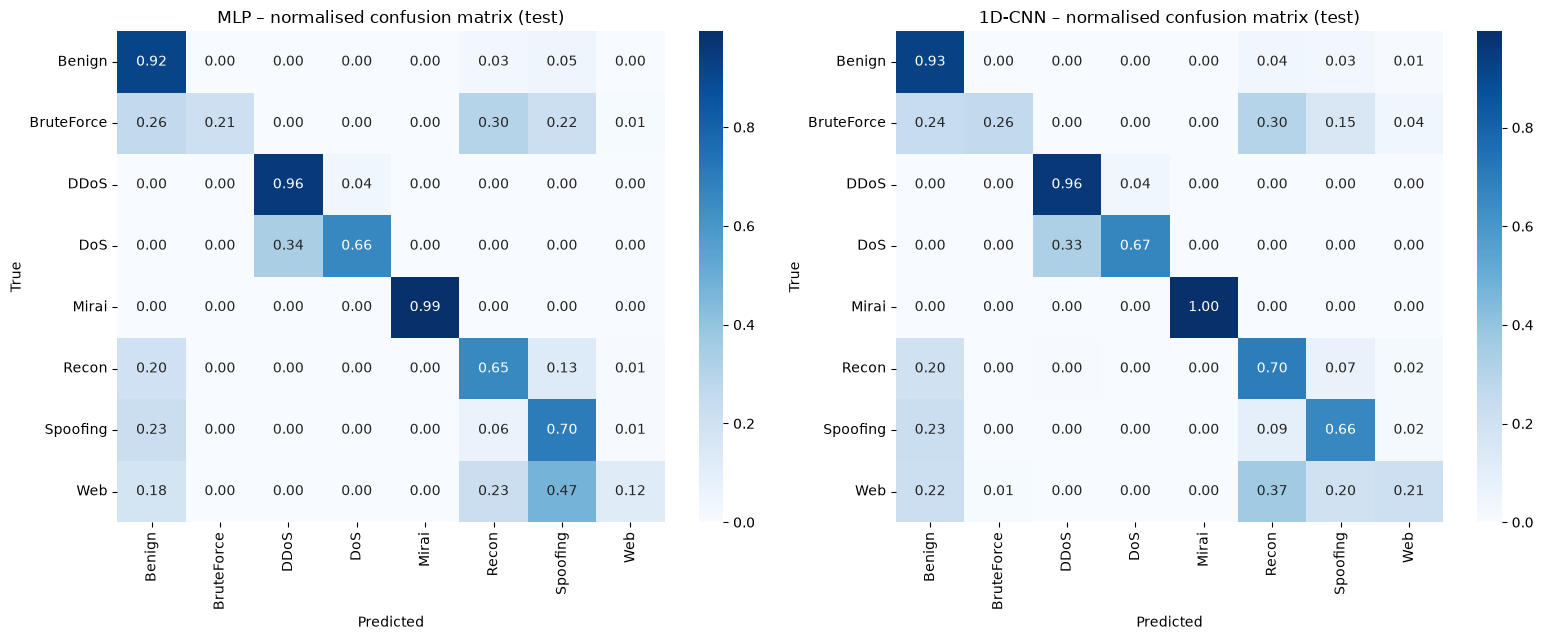

In [17]:
# Confusion matrices (row-normalised so rare classes are readable)
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, name in zip(axes, ("MLP", "1D-CNN")):
    pred, _ = preds[(name, "test")]
    cm = confusion_matrix(y_test, pred, labels=np.arange(n_classes), normalize="true")
    sns.heatmap(cm, annot=n_classes <= 10, fmt=".2f", cmap="Blues", ax=ax, cbar=True,
                xticklabels=classes, yticklabels=classes)
    ax.set_title(f"{name} – normalised confusion matrix (test)")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout();  plt.show()

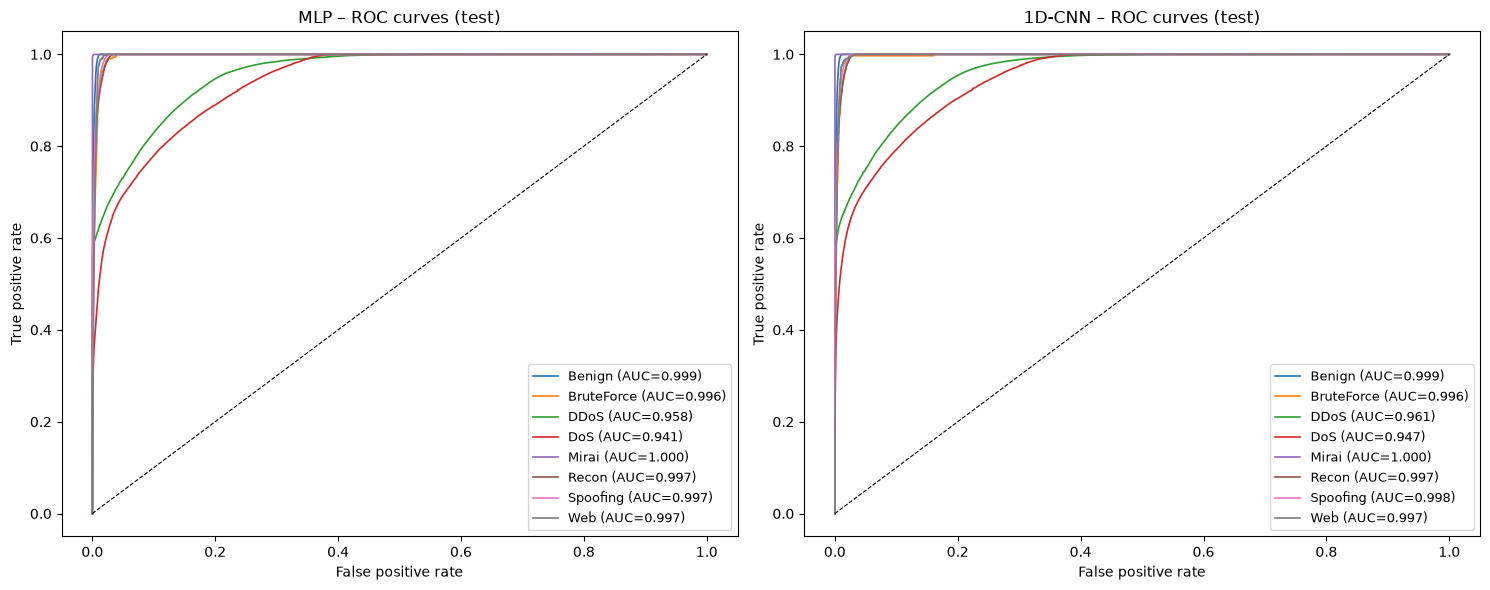

In [18]:
# ROC curves (one-vs-rest) on the test set
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
Yb = label_binarize(y_test, classes=np.arange(n_classes)) if n_classes > 2 else None
for ax, name in zip(axes, ("MLP", "1D-CNN")):
    _, proba = preds[(name, "test")]
    if n_classes == 2:
        fpr, tpr, _ = roc_curve(y_test, proba[:, 1]); ax.plot(fpr, tpr, label="Attack vs Benign")
    else:
        for i, c in enumerate(classes):
            if Yb[:, i].sum() == 0: continue
            fpr, tpr, _ = roc_curve(Yb[:, i], proba[:, i])
            ax.plot(fpr, tpr, lw=1.2, label=f"{c} (AUC={roc_auc_score(Yb[:, i], proba[:, i]):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_title(f"{name} – ROC curves (test)"); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.legend(fontsize=7 if n_classes > 10 else 9, loc="lower right")
plt.tight_layout();  plt.show()

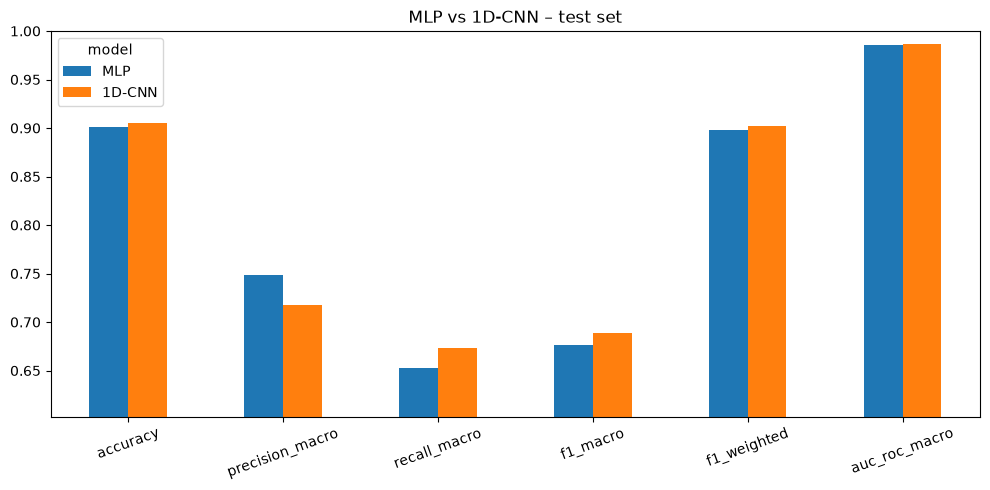

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,auc_roc_macro
model,,,,,,
MLP,0.9013,0.7482,0.6525,0.6767,0.8980,0.9856
1D-CNN,0.9056,0.7176,0.6729,0.6883,0.9024,0.9868


In [19]:
# Side-by-side comparison on the test set
cmp = results_df[results_df.split == "test"].set_index("model")[
    ["accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_weighted", "auc_roc_macro"]]
ax = cmp.T.plot(kind="bar", figsize=(10, 5), rot=20)
ax.set_ylim(max(0, cmp.values.min() - 0.05), 1.0); ax.set_title("MLP vs 1D-CNN – test set")
plt.tight_layout();  plt.show()
cmp

In [20]:
#observation 
# Save artefacts used
import joblib
mlp.save(f"{OUT_DIR}/mlp.keras"); cnn.save(f"{OUT_DIR}/cnn1d.keras")
joblib.dump(dict(scaler=scaler, feature_cols=feature_cols, skewed=skewed, classes=classes,
                 label_mode=LABEL_MODE), f"{OUT_DIR}/preprocessing.joblib")   # reused by Week 7
print("Saved results to", OUT_DIR, "->", sorted(os.listdir(OUT_DIR)))

Saved results to outputs_week6 -> ['classification_report_1D-CNN.csv', 'classification_report_MLP.csv', 'cnn1d.keras', 'metrics_summary.csv', 'mlp.keras', 'preprocessing.joblib']
